<a href="https://colab.research.google.com/github/deepak9344/crypto-currency-price-prediction/blob/main/crypto-currency%20price%20prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy scikit-learn matplotlib tensorflow

In [13]:
from google.colab import files
uploaded = files.upload()

Saving coin_Bitcoin.csv to coin_Bitcoin.csv


In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

df = pd.read_csv("coin_Bitcoin.csv")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").tail(2000).copy()

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna(subset=["Close"])
df = df[df["Close"] > 0]

print("Dataset loaded successfully!")
print("Number of records:", len(df))
print(df.head())

Dataset loaded successfully!
Number of records: 2000
     SNo     Name Symbol                Date        High         Low  \
991  992  Bitcoin    BTC 2016-01-15 23:59:59  430.255005  364.330994   
992  993  Bitcoin    BTC 2016-01-16 23:59:59  390.557007  354.914001   
993  994  Bitcoin    BTC 2016-01-17 23:59:59  390.964996  380.092010   
994  995  Bitcoin    BTC 2016-01-18 23:59:59  388.104004  376.665009   
995  996  Bitcoin    BTC 2016-01-19 23:59:59  387.730011  378.971985   

           Open       Close       Volume     Marketcap  
991  430.255005  364.330994  153351008.0  5.496598e+09  
992  365.072998  387.536011  120352000.0  5.848064e+09  
993  387.152008  382.299011   45319600.0  5.770478e+09  
994  381.733002  387.167999   54403900.0  5.845656e+09  
995  387.026001  380.148987   46819800.0  5.740934e+09  


In [17]:
from sklearn.preprocessing import MinMaxScaler

# Select closing prices
prices = df[["Close"]].values

# Normalize prices between 0 and 1
scaler = MinMaxScaler()
scaled = scaler.fit_transform(prices)

print("Scaled data shape:", scaled.shape)
print("Scaling completed successfully!")

Scaled data shape: (2000, 1)
Scaling completed successfully!


In [18]:
X, y = [], []

for i in range(7, len(scaled)):
    X.append(scaled[i-7:i])
    y.append(scaled[i, 0])

import numpy as np

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1993, 7, 1)
y shape: (1993,)


In [20]:
# Chronological 80/20 train-test split
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1594, 7, 1)
X_test: (399, 7, 1)
y_train: (1594,)
y_test: (399,)


In [21]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0020 - val_loss: 7.1422e-04
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0021 - val_loss: 1.3274e-04
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 9.5270e-05
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4.7725e-04 - val_loss: 1.4256e-04
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2.1735e-04 - val_loss: 1.1600e-04
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.7639e-04 - val_loss: 9.0217e-05
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.4914e-04 - val_loss: 8.6695e-05
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.5642e-04 - val_loss: 8.8763e-05
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.6476e-04 - val_loss: 8.4473e-05
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.5343e-04 - val_loss: 9.0221e-05
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.8148e-04 - val_loss: 8.565

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(50, input_shape=(7, 1)),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0021 - val_loss: 6.2425e-04
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0023 - val_loss: 1.5685e-04
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 - val_loss: 9.9054e-05
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 4.7786e-04 - val_loss: 1.2575e-04
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.7162e-04 - val_loss: 1.4137e-04
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.0804e-04 - val_loss: 1.0849e-04
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.7511e-04 - val_loss: 9.4217e-05
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.8506e-04 - val_loss: 9.2355e-05
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.7744e-04 - val_loss: 9.0150e-05
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.7937e-04 - val_loss: 8.9661e-05
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.7050e-04 - val_loss: 8.8329e-

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

pred = model.predict(X_test)

actual = scaler.inverse_transform(y_test.reshape(-1, 1))
predicted = scaler.inverse_transform(pred)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", mae)
print("RMSE:", rmse)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step
MAE: 1727.3990578628448
RMSE: 2577.491493412039


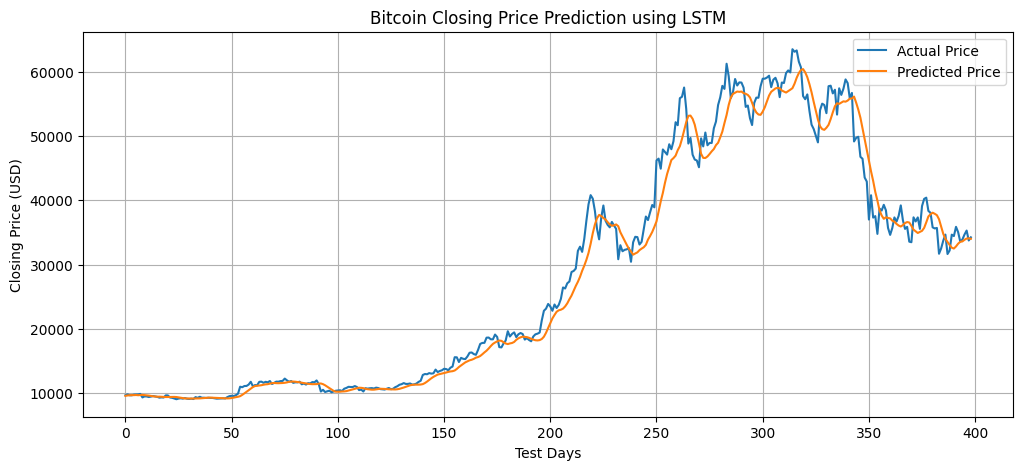

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual Price")
plt.plot(predicted, label="Predicted Price")
plt.title("Bitcoin Closing Price Prediction using LSTM")
plt.xlabel("Test Days")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()